**Лабораторная работа 04**

**Часть 1. Гипотезы**

**ФИО**: Ушакова Марина Михайловна

**Группа**: ЕТ-212

1. Загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_excel('Пренатальная диагностика.xlsx', sheet_name='исходные данные')
print(df.shape)
print(df.head())
print(df.dtypes)

(1050, 7)
   vozrast  gr-dni  ctr   nt  rost   ves  pol(1-м, 0-д)
0       18      70   61  1.3    48  3100              0
1       22      72   50  0.9    50  3400              0
2       29      73   45  0.9    53  3500              1
3       28      74   47  1.1    50  3490              1
4       31      74   46  1.3    53  3590              0
vozrast            int64
gr-dni             int64
ctr                int64
nt               float64
rost               int64
ves                int64
pol(1-м, 0-д)      int64
dtype: object


2. Сколько родилось мальчиков и девочек

In [2]:
counts = df['pol(1-м, 0-д)'].value_counts().sort_index()
boys  = counts.get(1, 0)
girls = counts.get(0, 0)
print(f"Мальчики: {boys}")
print(f"Девочки:  {girls}")
print(f"Всего:    {len(df)}")

Мальчики: 577
Девочки:  473
Всего:    1050


3. Столбец ИМТ

ИМТ для новорождённых считается по той же формуле, что и для взрослых: вес (кг) / рост (м)². Вес в граммах → делим на 1000.

In [3]:
df['IMT'] = (df['ves'] / 1000) / (df['rost'] / 100) ** 2
print(df[['rost', 'ves', 'IMT']].head())

   rost   ves        IMT
0    48  3100  13.454861
1    50  3400  13.600000
2    53  3500  12.459950
3    50  3490  13.960000
4    53  3590  12.780349


4. Числовые характеристики

In [4]:
num_cols = ['vozrast', 'gr-dni', 'ctr', 'nt', 'rost', 'ves', 'IMT']
desc = df[num_cols].describe().T          # count, mean, std, min, 25%, 50%, 75%, max
desc['median'] = df[num_cols].median()
desc['range']  = df[num_cols].max() - df[num_cols].min()
desc['skew']   = df[num_cols].skew()
desc['kurt']   = df[num_cols].kurt()      # excess kurtosis (норма = 0)
print(desc)

          count         mean         std          min          25%  \
vozrast  1050.0    28.681905    5.406432    16.000000    25.000000   
gr-dni   1050.0    88.764762    6.314969    70.000000    84.000000   
ctr      1050.0    64.125714   10.449999    45.000000    56.000000   
nt       1050.0     1.337333    0.397701     0.300000     1.100000   
rost     1050.0    51.698095    2.087069    45.000000    50.000000   
ves      1050.0  3435.779048  399.315445  2410.000000  3150.000000   
IMT      1050.0    12.829898    1.017828     8.686365    12.110727   

                 50%          75%          max       median        range  \
vozrast    28.000000    33.000000    45.000000    28.000000    29.000000   
gr-dni     88.000000    93.000000   108.000000    88.000000    38.000000   
ctr        64.000000    72.000000    85.000000    64.000000    40.000000   
nt          1.300000     1.600000     2.800000     1.300000     2.500000   
rost       52.000000    53.000000    60.000000    52.000000

5. Проверка на нормальность

a. Гистограмма + KDE

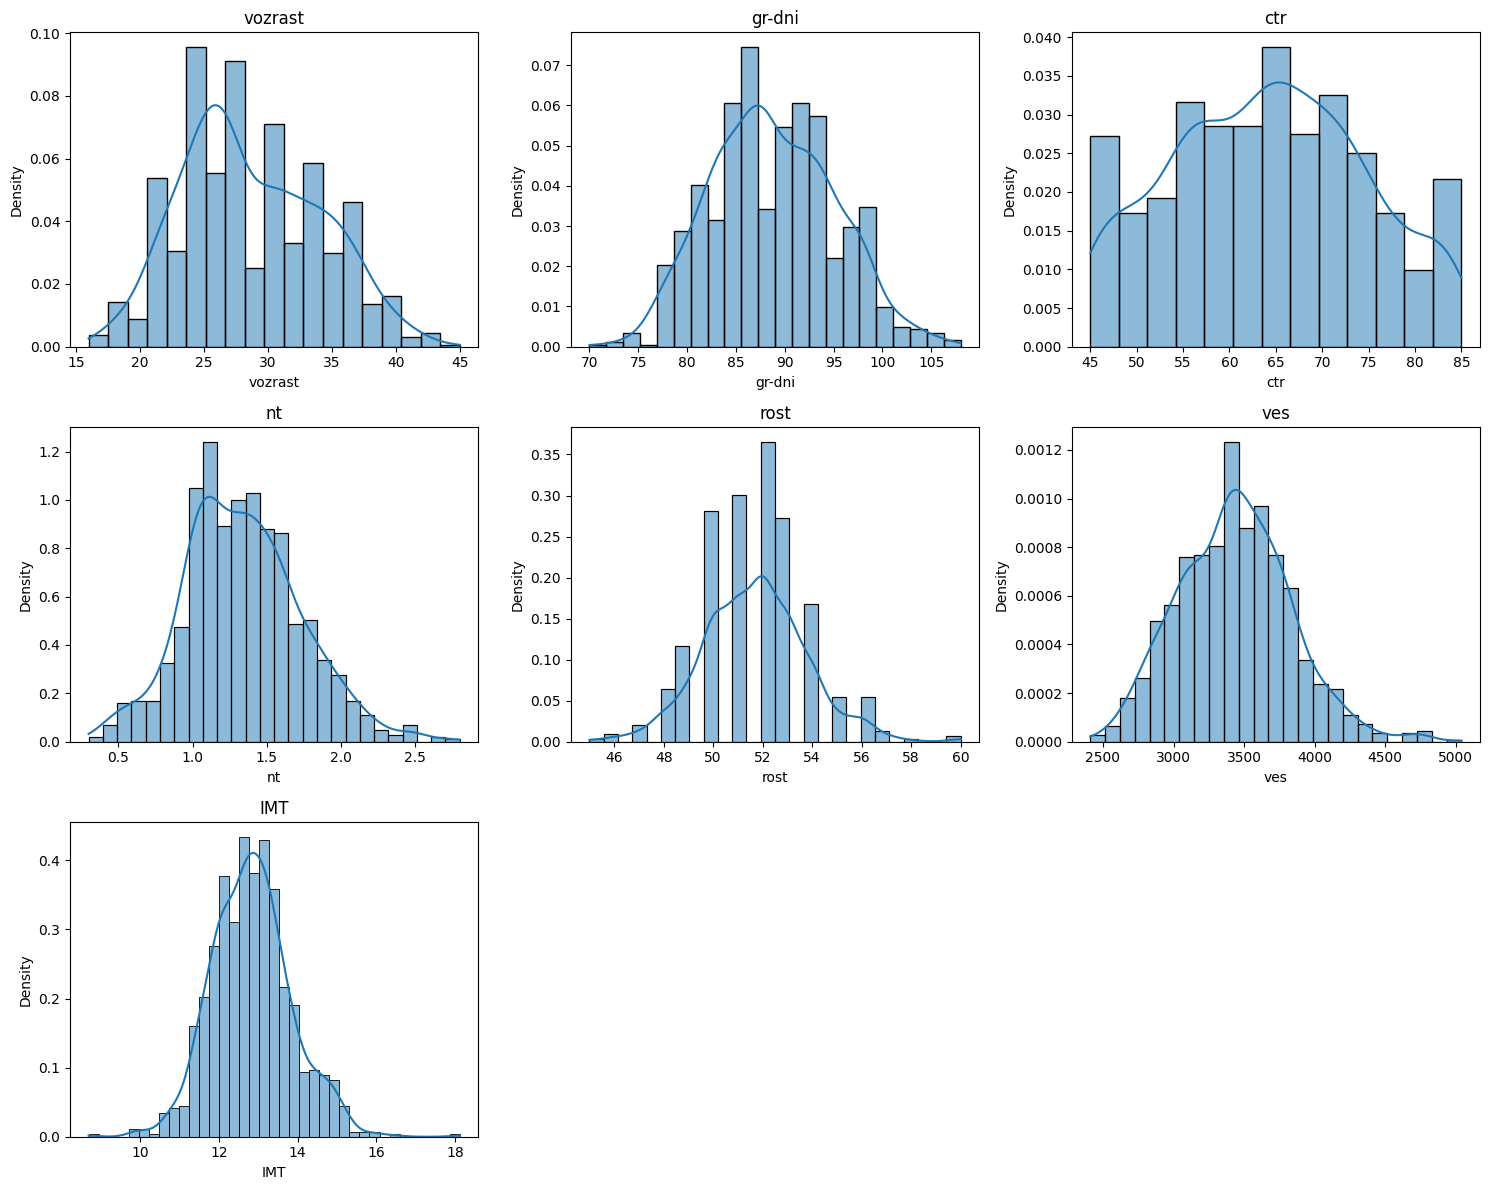

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], stat='density')
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

b. Асимметрия и эксцесс

При нормальном распределении: асимметрия (skewness) = 0, эксцесс (excess kurtosis) = 0.
На практике значения в пределах примерно ±0.5–1 считаются «близкими к нормальным».

In [6]:
norm_stats = pd.DataFrame({
    'skew': df[num_cols].skew(),
    'kurt (excess)': df[num_cols].kurt()
})
print(norm_stats)

             skew  kurt (excess)
vozrast  0.278528      -0.595901
gr-dni   0.163237      -0.349594
ctr      0.036253      -0.817104
nt       0.329712       0.303430
rost     0.230543       0.819221
ves      0.326097       0.385348
IMT      0.291300       0.944273


c. Критерии нормальности (α = 0.05)

Используем Шапиро–Уилка (лучший для n < 5000) и, для полноты, Д'Агостино–Пирсона (normaltest).


In [7]:
results = []
for col in num_cols:
    x = df[col].dropna()
    sh_w, sh_p = stats.shapiro(x)
    dp_stat, dp_p = stats.normaltest(x)
    results.append({
        'column': col,
        'Shapiro W': sh_w, 'Shapiro p': sh_p,
        "D'Agostino p": dp_p,
        'normal (p>0.05)?': 'да' if sh_p > 0.05 else 'нет'
    })
norm_df = pd.DataFrame(results)
print(norm_df)

    column  Shapiro W     Shapiro p  D'Agostino p normal (p>0.05)?
0  vozrast   0.980773  1.468351e-10  1.215833e-10              нет
1   gr-dni   0.992675  4.659237e-05  2.141619e-03              нет
2      ctr   0.977383  1.006610e-11  4.906483e-21              нет
3       nt   0.985847  1.495901e-08  1.942396e-05              нет
4     rost   0.972701  3.697210e-13  2.875790e-06              нет
5      ves   0.990988  4.890124e-06  1.023583e-05              нет
6      IMT   0.990336  2.160837e-06  3.315284e-08              нет


Вывод: при α=0.05 для большинства показателей (кроме, возможно, nt, ctr) гипотеза о нормальности отвергается — распределения скошены.

6. Гендерные различия

Выбор теста — ключевой момент

Если обе выборки нормальны и дисперсии равны → Student t-test (equal_var=True).

Если нормальны, но дисперсии разные → Welch t-test (equal_var=False).

Если нормальность нарушена → Mann–Whitney U (непараметрический аналог).

Проверим нормальность отдельно по группам и равенство дисперсий (Левен), затем автоматически выберем тест.

In [8]:
def compare_by_gender(col):
    boys  = df.loc[df['pol(1-м, 0-д)'] == 1, col].dropna()
    girls = df.loc[df['pol(1-м, 0-д)'] == 0, col].dropna()

    # нормальность в каждой группе
    p_b = stats.shapiro(boys).pvalue
    p_g = stats.shapiro(girls).pvalue
    normal = (p_b > 0.05) and (p_g > 0.05)

    # равенство дисперсий
    lev_p = stats.levene(boys, girls).pvalue
    equal_var = lev_p > 0.05

    if normal:
        test_name = 'Student t' if equal_var else 'Welch t'
        t, p = stats.ttest_ind(boys, girls, equal_var=equal_var)
    else:
        test_name = 'Mann-Whitney U'
        t, p = stats.mannwhitneyu(boys, girls, alternative='two-sided')

    return {
        'column': col,
        'n_boys': len(boys), 'n_girls': len(girls),
        'mean_boys': boys.mean(), 'mean_girls': girls.mean(),
        'median_boys': boys.median(), 'median_girls': girls.median(),
        'shapiro_p_boys': p_b, 'shapiro_p_girls': p_g,
        'levene_p': lev_p,
        'test': test_name,
        'statistic': t, 'p-value': p,
        'difference (p<0.05)?': 'есть' if p < 0.05 else 'нет'
    }

gender_results = pd.DataFrame([compare_by_gender(c) for c in ['rost', 'ves', 'IMT']])
print(gender_results.T)

                                   0               1               2
column                          rost             ves             IMT
n_boys                           577             577             577
n_girls                          473             473             473
mean_boys                  52.001733     3497.455806       12.906159
mean_girls                 51.327696     3360.541226       12.736868
median_boys                     52.0          3490.0       12.906805
median_girls                    51.0          3370.0        12.70304
shapiro_p_boys                   0.0        0.000142        0.081358
shapiro_p_girls                  0.0        0.014827             0.0
levene_p                    0.779693        0.064879        0.034388
test                  Mann-Whitney U  Mann-Whitney U  Mann-Whitney U
statistic                   163694.0        163007.0        151459.0
p-value                          0.0             0.0        0.002157
difference (p<0.05)?            ес